# ML Assignment 2 - Wall Following Robot Navigation

Dataset: UCI Wall-Following Robot Navigation (24 ultrasound sensors, 5456 rows, 4 movement classes).
Models: Logistic Regression, Decision Tree, KNN, Naive Bayes and SVM.
The rows are recorded in time order, so I used the first 80% of rows for training and the last 20% for testing.

In [2]:
%pip install -q numpy==2.3.4 scipy==1.16.3 pandas==2.3.3 scikit-learn==1.7.2 matplotlib==3.10.6 seaborn==0.13.2 joblib==1.5.2

Note: you may need to restart the kernel to use updated packages.


In [3]:
import os, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib, sklearn

from sklearn.base import clone
from sklearn.model_selection import train_test_split, GridSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score, recall_score,
                             f1_score, matthews_corrcoef, confusion_matrix, classification_report)

RANDOM_STATE = 16
DATA_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/00194/sensor_readings_24.data"
LOCAL_DATA = "sensor_readings_24.data"   # used instead of the URL if this file is next to the notebook
FEATURES = [f"US{i}" for i in range(1, 25)]   # US1 to US24
TARGET = "Movement"
CLASS_ORDER = ["Move-Forward", "Sharp-Right-Turn", "Slight-Right-Turn", "Slight-Left-Turn"]
TEST_FRACTION = 0.20

# output folder next to the notebook (models, test_data.csv and result csv files go here)
OUT_DIR = "output"
MODEL_DIR = f"{OUT_DIR}/model"
os.makedirs(MODEL_DIR, exist_ok=True)
print("Output folder:", os.path.abspath(OUT_DIR))

print("sklearn:", sklearn.__version__, " pandas:", pd.__version__, " numpy:", np.__version__)

Output folder: /home/s2026ak05411/workspace/output
sklearn: 1.7.2  pandas: 2.2.3  numpy: 2.5.4


In [4]:
# file has no header. first 24 columns are sensors, last one is the label
data_path = LOCAL_DATA if os.path.exists(LOCAL_DATA) else DATA_URL
print("Reading data from:", data_path)
raw_df = pd.read_csv(data_path, header=None, names=FEATURES + [TARGET])

print("Shape:", raw_df.shape)
print("Duplicate rows:", raw_df.duplicated().sum())
print("Missing values:", raw_df.isna().sum().sum())
raw_df.info()
display(raw_df.head())

Reading data from: https://archive.ics.uci.edu/ml/machine-learning-databases/00194/sensor_readings_24.data
Shape: (5456, 25)
Duplicate rows: 0
Missing values: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5456 entries, 0 to 5455
Data columns (total 25 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   US1       5456 non-null   float64
 1   US2       5456 non-null   float64
 2   US3       5456 non-null   float64
 3   US4       5456 non-null   float64
 4   US5       5456 non-null   float64
 5   US6       5456 non-null   float64
 6   US7       5456 non-null   float64
 7   US8       5456 non-null   float64
 8   US9       5456 non-null   float64
 9   US10      5456 non-null   float64
 10  US11      5456 non-null   float64
 11  US12      5456 non-null   float64
 12  US13      5456 non-null   float64
 13  US14      5456 non-null   float64
 14  US15      5456 non-null   float64
 15  US16      5456 non-null   float64
 16  US17      5456 non-null  

,US1,US2,US3,US4,US5,US6,US7,US8,US9,US10,...,US16,US17,US18,US19,US20,US21,US22,US23,US24,Movement
0,0.438,0.498,3.625,3.645,5.0,2.918,5.0,2.351,2.332,2.643,...,0.593,0.502,0.493,0.504,0.445,0.431,0.444,0.440,0.429,Slight-Right-Turn
1,0.438,0.498,3.625,3.648,5.0,2.918,5.0,2.637,2.332,2.649,...,0.592,0.502,0.493,0.504,0.449,0.431,0.444,0.443,0.429,Slight-Right-Turn
2,0.438,0.498,3.625,3.629,5.0,2.918,5.0,2.637,2.334,2.643,...,0.593,0.502,0.493,0.504,0.449,0.431,0.444,0.446,0.429,Slight-Right-Turn
3,0.437,0.501,3.625,3.626,5.0,2.918,5.0,2.353,2.334,2.642,...,0.593,0.502,0.493,0.504,0.449,0.431,0.444,0.444,0.429,Slight-Right-Turn
4,0.438,0.498,3.626,3.629,5.0,2.918,5.0,2.640,2.334,2.639,...,0.592,0.502,0.493,0.504,0.449,0.431,0.444,0.441,0.429,Slight-Right-Turn


,feature,type,description
0,US1,numeric,ultrasound sensor 1 distance (m)
1,US2,numeric,ultrasound sensor 2 distance (m)
2,US3,numeric,ultrasound sensor 3 distance (m)
3,US4,numeric,ultrasound sensor 4 distance (m)
4,US5,numeric,ultrasound sensor 5 distance (m)
5,US6,numeric,ultrasound sensor 6 distance (m)
6,US7,numeric,ultrasound sensor 7 distance (m)
7,US8,numeric,ultrasound sensor 8 distance (m)
8,US9,numeric,ultrasound sensor 9 distance (m)
9,US10,numeric,ultrasound sensor 10 distance (m)


,count,mean,std,min,25%,50%,75%,max
US1,5456.0,1.471617,0.802801,0.400,0.92100,1.3350,1.81400,5.000
US2,5456.0,2.327043,1.410146,0.437,1.36200,1.9045,2.68150,5.025
US3,5456.0,2.489347,1.247435,0.470,1.53875,2.0640,2.73925,5.029
US4,5456.0,2.796501,1.309368,0.833,1.73100,2.4580,4.09350,5.017
US5,5456.0,2.958552,1.339225,1.120,1.77400,2.6670,4.31450,5.000
US6,5456.0,2.893073,1.282575,1.114,1.78575,2.6825,3.83525,5.005
US7,5456.0,3.351113,1.413692,1.122,1.93075,3.2255,5.00000,5.008
US8,5456.0,2.540397,1.111554,0.859,1.61800,2.1720,3.19300,5.087
US9,5456.0,3.125621,1.356965,0.836,1.79975,2.8020,5.00000,5.000
US10,5456.0,2.832386,1.307843,0.810,1.63600,2.6790,3.52625,5.022


                   count   share
Movement                        
Move-Forward        2205  0.4041
Sharp-Right-Turn    2097  0.3843
Slight-Right-Turn    826  0.1514
Slight-Left-Turn     328  0.0601


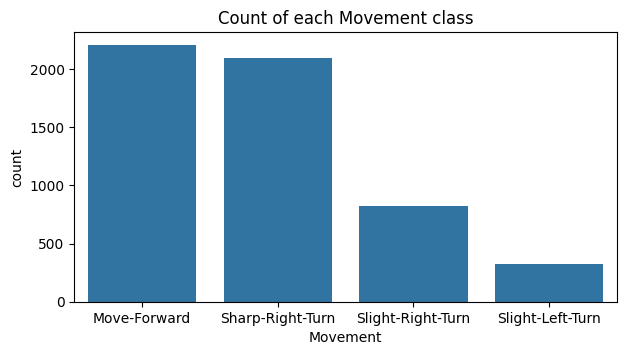

Number of label streaks: 396
Median streak length: 6.5


In [5]:
# all 24 features are numeric (distance in metres)
feature_types = pd.DataFrame({"feature": FEATURES, "type": "numeric",
                              "description": [f"ultrasound sensor {i} distance (m)" for i in range(1, 25)]})
display(feature_types)
display(raw_df[FEATURES].describe().T)

# class distribution
class_counts = raw_df[TARGET].value_counts().reindex(CLASS_ORDER)
print(pd.DataFrame({"count": class_counts, "share": (class_counts / len(raw_df)).round(4)}))
plt.figure(figsize=(7, 3.5))
sns.countplot(x=TARGET, data=raw_df, order=CLASS_ORDER)
plt.title("Count of each Movement class")
plt.show()

# same label repeats for a few rows at a time, so the rows are in time order
streak_id = (raw_df[TARGET] != raw_df[TARGET].shift()).cumsum()
print("Number of label streaks:", streak_id.nunique())
print("Median streak length:", raw_df.groupby(streak_id).size().median())

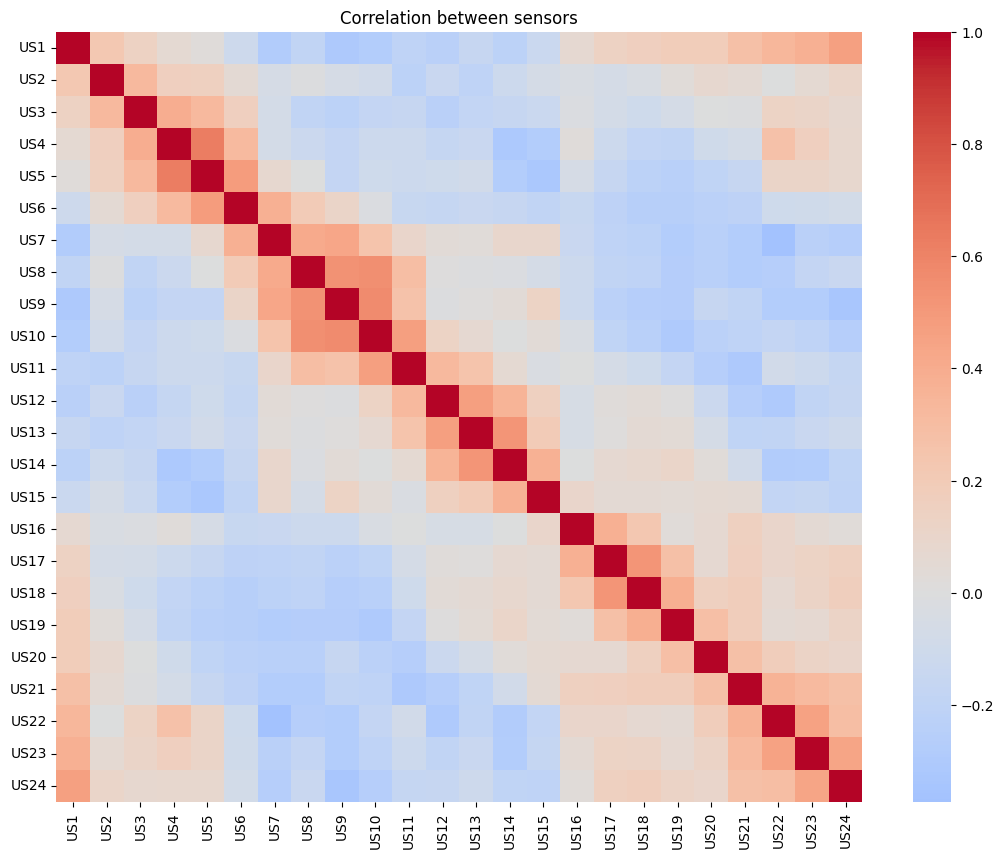

Top 6 sensors by F score:
US15    654.3
US20    347.5
US19    301.1
US24    226.0
US18    209.1
US17    208.3
dtype: float64


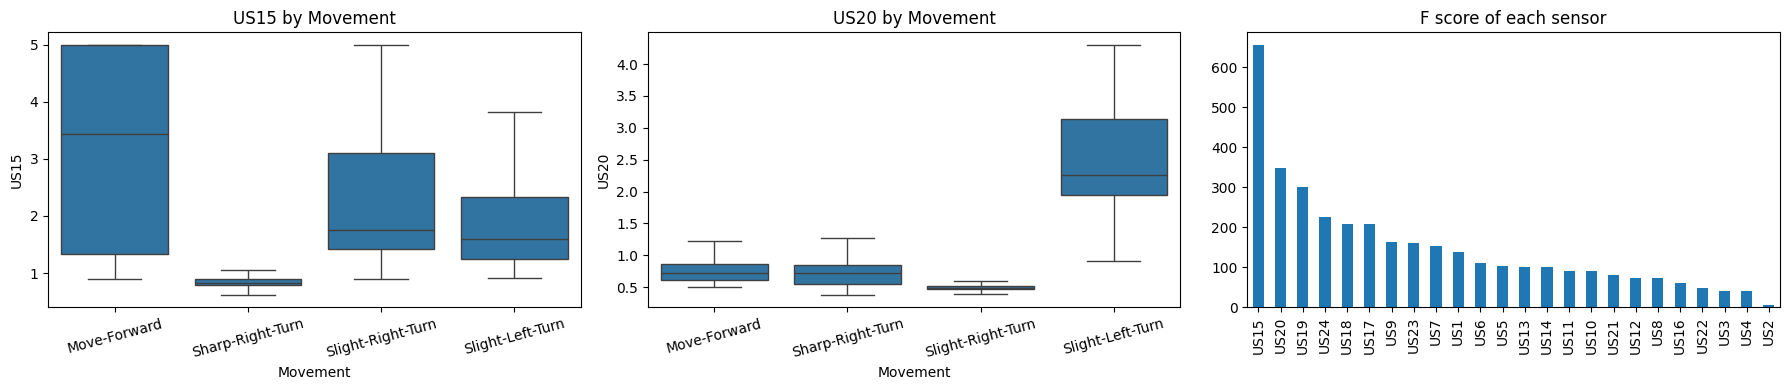

Median distance between consecutive rows: 3.31
Median distance between random pairs: 8.66


In [6]:
# correlation heatmap
plt.figure(figsize=(13, 10))
sns.heatmap(raw_df[FEATURES].corr(), cmap="coolwarm", center=0)
plt.title("Correlation between sensors")
plt.show()

# ANOVA F score - higher means the sensor separates the classes better
f_scores, _ = f_classif(raw_df[FEATURES], raw_df[TARGET])
f_rank = pd.Series(f_scores, index=FEATURES).sort_values(ascending=False)
print("Top 6 sensors by F score:")
print(f_rank.head(6).round(1))

# boxplots of the top 2 sensors and bar chart of all F scores
top2 = list(f_rank.index[:2])
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for i, col in enumerate(top2):
    sns.boxplot(x=TARGET, y=col, data=raw_df, order=CLASS_ORDER, ax=axes[i], showfliers=False)
    axes[i].set_title(col + " by Movement")
    axes[i].tick_params(axis="x", rotation=15)
f_rank.plot(kind="bar", ax=axes[2])
axes[2].set_title("F score of each sensor")
plt.tight_layout()
plt.show()

# check if consecutive rows are similar (if yes, a random split is not ok)
vals = raw_df[FEATURES].values
rng = np.random.default_rng(RANDOM_STATE)
consec_dist = np.median(np.linalg.norm(np.diff(vals, axis=0), axis=1))
random_dist = np.median(np.linalg.norm(vals[rng.permutation(len(vals))] - vals, axis=1))
print("Median distance between consecutive rows:", round(consec_dist, 2))
print("Median distance between random pairs:", round(random_dist, 2))

In [7]:
# consecutive rows are almost the same reading, so a random split would put
# near duplicates of train rows in the test set.
# so I am using the first 80% rows for training and the last 20% for testing (no shuffle)
cut = int(len(raw_df) * (1 - TEST_FRACTION))
train_df = raw_df.iloc[:cut]
test_df = raw_df.iloc[cut:]
X_train, y_train = train_df[FEATURES], train_df[TARGET]
X_test, y_test = test_df[FEATURES], test_df[TARGET]
print("Train:", X_train.shape, " Test:", X_test.shape)

# class share in train and test
mix = pd.DataFrame({"overall": raw_df[TARGET].value_counts(normalize=True),
                    "train": y_train.value_counts(normalize=True),
                    "test": y_test.value_counts(normalize=True),
                    "test rows": y_test.value_counts()}).reindex(CLASS_ORDER).round(3)
display(mix.reset_index(names="class"))

# no missing values here, but kept the imputer in case an uploaded csv in the app has blanks
def make_preprocessor():
    return Pipeline([("impute", SimpleImputer(strategy="mean")), ("scale", StandardScaler())])

Train: (4364, 24)  Test: (1092, 24)


,class,overall,train,test,test rows
0,Move-Forward,0.404,0.407,0.393,429
1,Sharp-Right-Turn,0.384,0.387,0.374,408
2,Slight-Right-Turn,0.151,0.155,0.136,148
3,Slight-Left-Turn,0.060,0.051,0.098,107


In [8]:
# hyperparameter tuning with GridSearchCV (on train data only)
# TimeSeriesSplit keeps the time order, validation rows always come after training rows
# n_splits=4 because with 5 the first fold has no Slight-Left-Turn rows in training
# gap=10 leaves out 10 rows between train and validation in each fold, because rows next to each
# other are almost the same (a label lasts about 6.5 rows), so validation does not start on near copies
# scoring = macro F1 so the small classes also matter
tscv = TimeSeriesSplit(n_splits=4, gap=10)

# check each fold: sizes and Slight-Left-Turn rows in training
for i, (tr, va) in enumerate(tscv.split(X_train)):
    print(f"fold {i}: train rows 0-{tr[-1]}, validation rows {va[0]}-{va[-1]}, "
          f"Slight-Left-Turn in train: {(y_train.iloc[tr] == 'Slight-Left-Turn').sum()}")

# class_weight="balanced" for LR, DT and SVM as Slight-Left-Turn is only 6% of data
# (KNN and Naive Bayes don't have class_weight)
search_space = {
    "Logistic Regression": (LogisticRegression(max_iter=5000, class_weight="balanced", random_state=RANDOM_STATE),
                            {"clf__C": [0.01, 0.1, 1, 10, 100]}),
    "Decision Tree": (DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE),
                      {"clf__max_depth": [4, 6, 8, 10, 12], "clf__min_samples_leaf": [1, 5, 10, 20]}),
    "KNN": (KNeighborsClassifier(),
            {"clf__n_neighbors": [3, 5, 7, 11, 15, 21], "clf__weights": ["uniform", "distance"]}),
    "Naive Bayes": (GaussianNB(),
                    {"clf__var_smoothing": [1e-9, 1e-7, 1e-5, 1e-3, 1e-2, 1e-1]}),
    # probability=False during search to save time, turned on for the final model
    "Support Vector Machine": (SVC(kernel="rbf", class_weight="balanced", random_state=RANDOM_STATE),
                               {"clf__C": [0.3, 1, 3, 10, 30, 100], "clf__gamma": ["scale", 0.01, 0.03, 0.1]}),
}

models = {}
tuning_rows = []
for name, (est, grid) in search_space.items():
    start = time.time()
    pipe = Pipeline([("prep", make_preprocessor()), ("clf", est)])
    search = GridSearchCV(pipe, grid, cv=tscv, scoring="f1_macro", n_jobs=-1)
    search.fit(X_train, y_train)

    best_clf = clone(search.best_estimator_.named_steps["clf"])
    if name == "Support Vector Machine":
        best_clf.set_params(probability=True)
    models[name] = best_clf

    best_params = {k.replace("clf__", ""): v for k, v in search.best_params_.items()}
    tuning_rows.append({"ML Model Name": name,
                        "best params": str(best_params),
                        "CV macro F1 (mean)": round(search.best_score_, 4),
                        "CV macro F1 (std)": round(search.cv_results_["std_test_score"][search.best_index_], 4),
                        "combinations tried": len(search.cv_results_["params"]),
                        "seconds": round(time.time() - start, 1)})

tuning_df = pd.DataFrame(tuning_rows)
display(tuning_df)

fold 0: train rows 0-865, validation rows 876-1747, Slight-Left-Turn in train: 38
fold 1: train rows 0-1737, validation rows 1748-2619, Slight-Left-Turn in train: 95
fold 2: train rows 0-2609, validation rows 2620-3491, Slight-Left-Turn in train: 116
fold 3: train rows 0-3481, validation rows 3492-4363, Slight-Left-Turn in train: 183


,ML Model Name,best params,CV macro F1 (mean),CV macro F1 (std),combinations tried,seconds
0,Logistic Regression,{'C': 10},0.5676,0.0426,5,5.4
1,Decision Tree,"{'max_depth': 10, 'min_samples_leaf': 1}",0.9476,0.0388,20,2.0
2,KNN,"{'n_neighbors': 5, 'weights': 'distance'}",0.6878,0.1056,12,0.9
3,Naive Bayes,{'var_smoothing': 0.001},0.5386,0.0199,6,0.3
4,Support Vector Machine,"{'C': 100, 'gamma': 0.03}",0.7929,0.0654,24,15.0


In [9]:
file_names = {"Logistic Regression": "logistic_regression", "Decision Tree": "decision_tree", "KNN": "knn",
              "Naive Bayes": "naive_bayes", "Support Vector Machine": "svm"}

# 4 classes, so precision / recall / F1 are macro average and AUC is one-vs-rest macro
def evaluate(y_true, y_pred, y_prob, classes):
    return {"Accuracy": accuracy_score(y_true, y_pred),
            "AUC": roc_auc_score(y_true, y_prob, multi_class="ovr", average="macro", labels=classes),
            "Precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
            "Recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
            "F1": f1_score(y_true, y_pred, average="macro", zero_division=0),
            "MCC": matthews_corrcoef(y_true, y_pred)}

# train each tuned model on the full train data, then test once on the test data
fitted, preds, results = {}, {}, []
for name, est in models.items():
    start = time.time()
    pipe = Pipeline([("prep", make_preprocessor()), ("clf", est)])
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)
    m = evaluate(y_test, y_pred, y_prob, pipe.classes_)

    fitted[name] = pipe
    preds[name] = y_pred
    results.append({"ML Model Name": name, **m})
    print(name, "done in", round(time.time() - start, 1), "sec")

metrics_df = pd.DataFrame(results).set_index("ML Model Name").round(4)
display(metrics_df.reset_index())

Logistic Regression done in 0.4 sec
Decision Tree done in 0.1 sec
KNN done in 0.2 sec
Naive Bayes done in 0.1 sec
Support Vector Machine done in 3.6 sec


,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.6658,0.9142,0.6509,0.7535,0.6612,0.5572
1,Decision Tree,0.9817,0.9949,0.9737,0.9872,0.9800,0.9734
2,KNN,0.8059,0.9366,0.7905,0.8103,0.7973,0.7197
3,Naive Bayes,0.5385,0.8645,0.5765,0.6797,0.5511,0.4308
4,Support Vector Machine,0.8947,0.9758,0.8949,0.8971,0.8950,0.8460


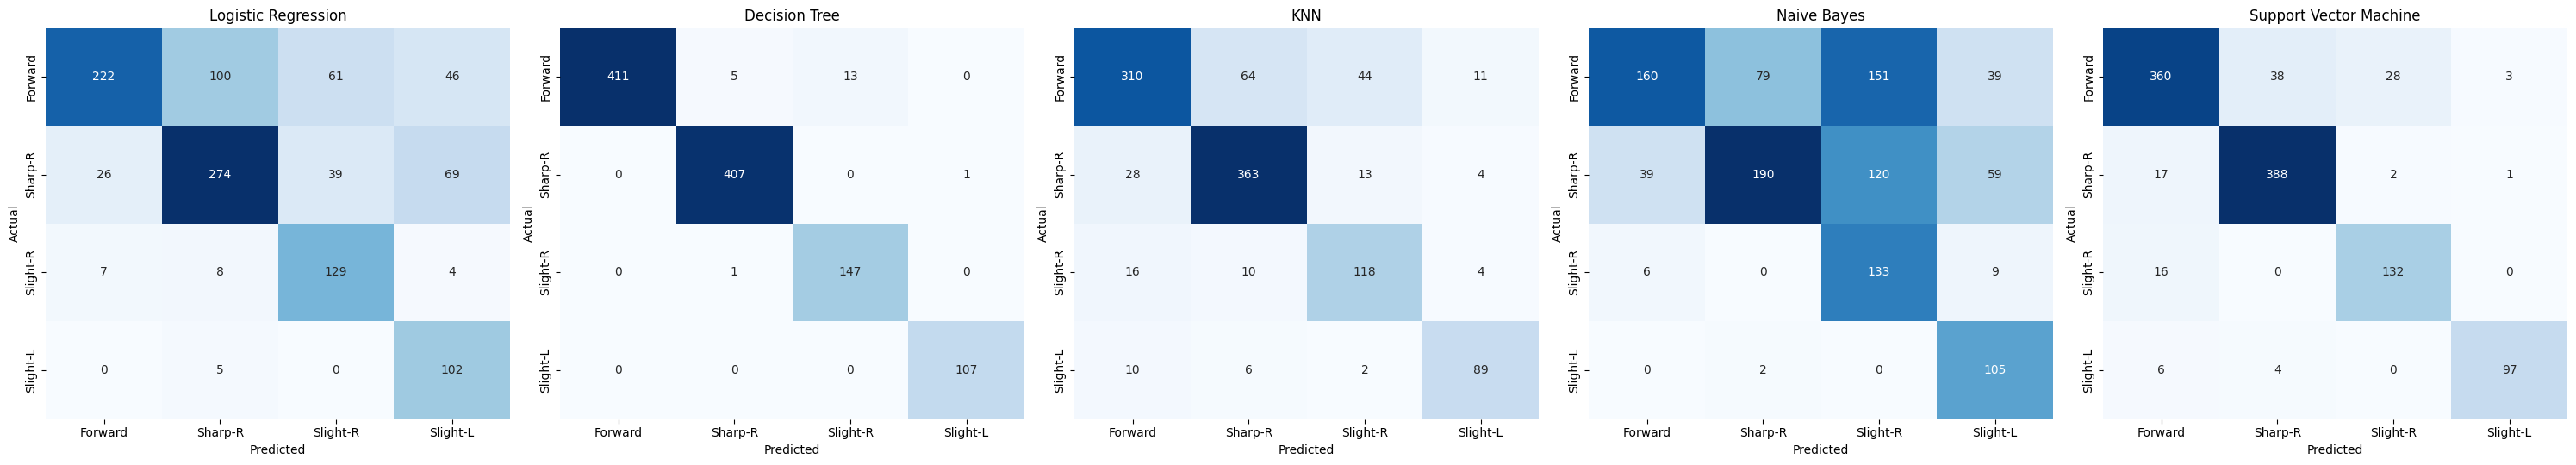

===== Logistic Regression =====
                   precision    recall  f1-score   support

     Move-Forward     0.8706    0.5175    0.6491       429
 Sharp-Right-Turn     0.7080    0.6716    0.6893       408
Slight-Right-Turn     0.5633    0.8716    0.6844       148
 Slight-Left-Turn     0.4615    0.9533    0.6220       107

         accuracy                         0.6658      1092
        macro avg     0.6509    0.7535    0.6612      1092
     weighted avg     0.7281    0.6658    0.6662      1092

===== Decision Tree =====
                   precision    recall  f1-score   support

     Move-Forward     1.0000    0.9580    0.9786       429
 Sharp-Right-Turn     0.9855    0.9975    0.9915       408
Slight-Right-Turn     0.9187    0.9932    0.9545       148
 Slight-Left-Turn     0.9907    1.0000    0.9953       107

         accuracy                         0.9817      1092
        macro avg     0.9737    0.9872    0.9800      1092
     weighted avg     0.9827    0.9817    0.9818    

In [10]:
# confusion matrix for each model
short_names = ["Forward", "Sharp-R", "Slight-R", "Slight-L"]
fig, axes = plt.subplots(1, 5, figsize=(30, 5.5))
for i, (name, y_pred) in enumerate(preds.items()):
    cm = confusion_matrix(y_test, y_pred, labels=CLASS_ORDER)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[i],
                xticklabels=short_names, yticklabels=short_names)
    axes[i].set_title(name)
    axes[i].set_xlabel("Predicted")
    axes[i].set_ylabel("Actual")
plt.tight_layout()
plt.show()

# classification report for each model
for name, y_pred in preds.items():
    print("=====", name, "=====")
    print(classification_report(y_test, y_pred, labels=CLASS_ORDER, digits=4, zero_division=0))

In [11]:
# only for comparison: same models on a normal random (stratified) 80/20 split,
# to see how much higher the scores look when the time order is ignored. these models are not saved.
Xr_train, Xr_test, yr_train, yr_test = train_test_split(raw_df[FEATURES], raw_df[TARGET], test_size=TEST_FRACTION,
                                                        stratify=raw_df[TARGET], random_state=RANDOM_STATE)
rand_rows = []
for name, est in models.items():
    p = Pipeline([("prep", make_preprocessor()), ("clf", clone(est))])
    p.fit(Xr_train, yr_train)
    rand_rows.append({"ML Model Name": name, **evaluate(yr_test, p.predict(Xr_test), p.predict_proba(Xr_test), p.classes_)})
random_df = pd.DataFrame(rand_rows).set_index("ML Model Name").round(4)

split_cmp = pd.DataFrame({"Accuracy (random)": random_df["Accuracy"], "Accuracy (ordered)": metrics_df["Accuracy"],
                          "MCC (random)": random_df["MCC"], "MCC (ordered)": metrics_df["MCC"]})
split_cmp["Accuracy drop"] = split_cmp["Accuracy (random)"] - split_cmp["Accuracy (ordered)"]
split_cmp["MCC drop"] = split_cmp["MCC (random)"] - split_cmp["MCC (ordered)"]
display(split_cmp.round(4).reset_index())

,ML Model Name,Accuracy (random),Accuracy (ordered),MCC (random),MCC (ordered),Accuracy drop,MCC drop
0,Logistic Regression,0.6859,0.6658,0.5711,0.5572,0.0201,0.0139
1,Decision Tree,0.9954,0.9817,0.9931,0.9734,0.0137,0.0197
2,KNN,0.8947,0.8059,0.8409,0.7197,0.0888,0.1212
3,Naive Bayes,0.5348,0.5385,0.3985,0.4308,-0.0037,-0.0323
4,Support Vector Machine,0.9341,0.8947,0.9002,0.8460,0.0394,0.0542


In [12]:
# save the 5 models (whole pipeline, so the scaler is saved with the model)
for name, pipe in fitted.items():
    joblib.dump(pipe, f"{MODEL_DIR}/{file_names[name]}.joblib")

# save test data, results and model info for the app
test_df[FEATURES + [TARGET]].to_csv(f"{OUT_DIR}/test_data.csv", index=False)
metrics_df.to_csv(f"{OUT_DIR}/model_metrics.csv")
split_cmp.round(4).to_csv(f"{OUT_DIR}/split_comparison.csv")
tuning_df.to_csv(f"{OUT_DIR}/tuning_results.csv", index=False)
with open(f"{MODEL_DIR}/model_info.json", "w") as f:
    json.dump({"dataset": "UCI Wall-Following Robot Navigation (24 sensors)", "features": FEATURES,
               "target": TARGET, "classes": CLASS_ORDER, "models": file_names,
               "split": "ordered: first 80% train, last 20% test", "sklearn_version": sklearn.__version__}, f, indent=2)

# list saved files
for root, _, files in os.walk(OUT_DIR):
    for fn in sorted(files):
        print(os.path.join(root, fn))

output/model_metrics.csv
output/split_comparison.csv
output/test_data.csv
output/tuning_results.csv
output/model/decision_tree.joblib
output/model/knn.joblib
output/model/logistic_regression.joblib
output/model/model_info.json
output/model/naive_bayes.joblib
output/model/svm.joblib


In [13]:
# load the saved models again and score test_data.csv (same steps as the streamlit app, no training)
chk = pd.read_csv(f"{OUT_DIR}/test_data.csv")
X_chk, y_chk = chk[FEATURES], chk[TARGET]
rows = []
for name, fn in file_names.items():
    mdl = joblib.load(f"{MODEL_DIR}/{fn}.joblib")
    rows.append({"ML Model Name": name, **evaluate(y_chk, mdl.predict(X_chk), mdl.predict_proba(X_chk), mdl.classes_)})
reload_df = pd.DataFrame(rows).set_index("ML Model Name").round(4)
print("Rows in test_data.csv:", len(chk))
print("Max difference from training run:", float((reload_df - metrics_df).abs().max().max()))
display(reload_df.reset_index())

Rows in test_data.csv: 1092
Max difference from training run: 0.0


,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.6658,0.9142,0.6509,0.7535,0.6612,0.5572
1,Decision Tree,0.9817,0.9949,0.9737,0.9872,0.9800,0.9734
2,KNN,0.8059,0.9366,0.7905,0.8103,0.7973,0.7197
3,Naive Bayes,0.5385,0.8645,0.5765,0.6797,0.5511,0.4308
4,Support Vector Machine,0.8947,0.9758,0.8949,0.8971,0.8950,0.8460
